In [ ]:
#ATTENTION
#the pd.read_csv uses a relative path
#so the csv file must be in same folder as this jupyter notebook


import pandas as pd                  # Read and work with tabular data
import numpy as np                   # Numerical operations
import matplotlib.pyplot as plt      # Graphs and visualizations

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# Display graphs inside the notebook
%matplotlib inline


In [ ]:
#ATTENTION
#the pd.read_csv uses a relative path
#so the csv file must be in same folder as this jupyter notebook

df = pd.read_csv(r'DataScience_salaries_2025.csv')
print("Dataset shape (rows, columns):", df.shape)
display(df.head())
display(df.info())
display(df.describe())

Dataset shape (rows, columns): (93597, 11)


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2025,MI,FT,Research Scientist,208000,USD,208000,US,0,US,M
1,2025,MI,FT,Research Scientist,147000,USD,147000,US,0,US,M
2,2025,SE,FT,Research Scientist,173000,USD,173000,US,0,US,M
3,2025,SE,FT,Research Scientist,117000,USD,117000,US,0,US,M
4,2025,MI,FT,AI Engineer,100000,USD,100000,US,100,US,M


<class 'pandas.DataFrame'>
RangeIndex: 93597 entries, 0 to 93596
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   work_year           93597 non-null  int64
 1   experience_level    93597 non-null  str  
 2   employment_type     93597 non-null  str  
 3   job_title           93597 non-null  str  
 4   salary              93597 non-null  int64
 5   salary_currency     93597 non-null  str  
 6   salary_in_usd       93597 non-null  int64
 7   employee_residence  93597 non-null  str  
 8   remote_ratio        93597 non-null  int64
 9   company_location    93597 non-null  str  
 10  company_size        93597 non-null  str  
dtypes: int64(4), str(7)
memory usage: 7.9 MB


None

,work_year,salary,salary_in_usd,remote_ratio
count,93597.000000,9.359700e+04,93597.000000,93597.000000
mean,2024.086434,1.623541e+05,157547.696774,21.455816
std,0.641449,2.221425e+05,73649.113729,40.954704
min,2020.000000,1.400000e+04,15000.000000,0.000000
25%,2024.000000,1.062600e+05,106250.000000,0.000000
50%,2024.000000,1.470000e+05,146232.000000,0.000000
75%,2024.000000,1.990000e+05,198000.000000,0.000000
max,2025.000000,3.040000e+07,800000.000000,100.000000


In [ ]:
df = df.drop_duplicates().copy()

target_column="salary_in_usd"
feature_columns=['experience_level', 'company_size','employment_type','job_title','company_location','work_year', 'remote_ratio']

ordinal_features = ['experience_level', 'company_size']
categorical_features = ['employment_type','job_title','company_location']
numeric_features = ['work_year', 'remote_ratio']

missing_columns = [
    col for col in [target_column] + feature_columns
    if col not in df.columns
]

if missing_columns:
    print("Error: These columns do not exist:", missing_columns)
else:
    print("Target:", target_column)
    print("Features:", feature_columns)
    display(df[[target_column] + feature_columns].head())

Target: salary_in_usd
Features: ['experience_level', 'company_size', 'employment_type', 'job_title', 'company_location', 'work_year', 'remote_ratio']


,salary_in_usd,experience_level,company_size,employment_type,job_title,company_location,work_year,remote_ratio
0,208000,MI,M,FT,Research Scientist,US,2025,0
1,147000,MI,M,FT,Research Scientist,US,2025,0
2,173000,SE,M,FT,Research Scientist,US,2025,0
3,117000,SE,M,FT,Research Scientist,US,2025,0
4,100000,MI,M,FT,AI Engineer,US,2025,100


In [ ]:
#Defining Model,X and y
model_df = df[feature_columns + [target_column]].copy()

model_df[target_column] = pd.to_numeric(model_df[target_column], errors="coerce")

model_df = model_df.dropna(subset=[target_column])

X = model_df[feature_columns]
y = model_df[target_column]



#Creating Pipelines for Each Feature type
ordinal_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        (
            'encoder',
            OrdinalEncoder(
                categories=[['EN', 'MI', 'SE', 'EX'], ['S', 'M', 'L']]
            ),
        ),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        (
            'onehot',
            OneHotEncoder(
                max_categories=10,
                drop='first',
                sparse_output=False,
                handle_unknown='ignore',
            ),
        ),
    ]
)

numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
)

# Combine into ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('ord', ordinal_transformer, ['experience_level', 'company_size']),
        (
            'cat_auto',
            categorical_transformer,
            ['employment_type', 'job_title', 'company_location'],
        ),
        ('num', numeric_transformer, ['work_year', 'remote_ratio']),
    ]
)

# Build & fit model pipeline
model = Pipeline(
    steps=[('preprocessor', preprocessor), ('regressor', LinearRegression())]
)

#Showing Some Basic information about the cleaned data
print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Ordinal features:", ordinal_features)
print("Rows available for modelling:", len(model_df))

Input shape: (46637, 7)
Target shape: (46637,)
Numeric features: ['work_year', 'remote_ratio']
Categorical features: ['employment_type', 'job_title', 'company_location']
Ordinal features: ['experience_level', 'company_size']
Rows available for modelling: 46637


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size = 0.2,
    random_state = 42
)

model.fit(X_train, y_train)

print("Model trained")


Model trained


R2 score: 0.23271343845938708
MAE: 49468.055185517165
MSE: 4527186769.050239


c:\Users\vyshn\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


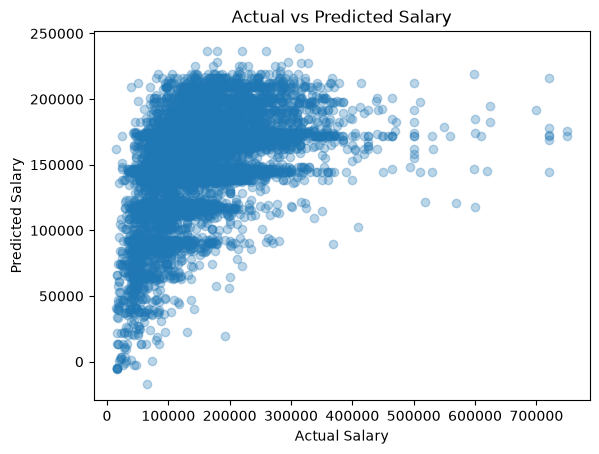

In [ ]:
# Predict salaries for the test data
y_pred = model.predict(X_test)

# Scores
print("R2 score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")
plt.savefig("predicted_vs_actual.png")
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Define salary threshold using median training salary
salary_threshold = y_train.median()

# Convert actual and predicted salaries into binary categories
actual_class = (y_test > salary_threshold).astype(int)
predicted_class = (y_pred > salary_threshold).astype(int)

# Calculate evaluation metrics
print("Accuracy :", accuracy_score(actual_class, predicted_class))
print("Precision:", precision_score(actual_class, predicted_class, zero_division=0))
print("Recall   :", recall_score(actual_class, predicted_class, zero_division=0))
print("F1 Score :", f1_score(actual_class, predicted_class, zero_division=0))

# Generate confusion matrix
conf_matrix = confusion_matrix(actual_class, predicted_class)
print("Confusion Matrix:\n", conf_matrix)

# Plot confusion matrix
plt.imshow(conf_matrix, cmap="Blues")
plt.colorbar()
plt.xticks([0, 1], ["Low", "High"])
plt.yticks([0, 1], ["Low", "High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (High vs Low Salary)")

for i in range(2):
    for j in range(2):
        plt.text(j, i, conf_matrix[i, j], ha="center", va="center")

plt.show()